In [1]:
# --- Workstream 1, Step 1: load the Bitext dataset and look at its structure ---
from datasets import load_dataset
import pandas as pd

ds = load_dataset("bitext/Bitext-customer-support-llm-chatbot-training-dataset", split="train")
bitext = ds.to_pandas()

print(bitext.shape)
print(bitext.columns.tolist())
print('\nCategories:', bitext.category.nunique(), ' Intents:', bitext.intent.nunique())
print(bitext.category.value_counts().to_string())
print('\nIntents per category:')
print(bitext.groupby('category').intent.unique().apply(lambda x: ', '.join(sorted(x))).to_string())
print('\nExample messages:')
print(bitext.sample(5, random_state=42)[['instruction', 'category', 'intent']].to_string())

README.md:   0%|          | 0.00/11.9k [00:00<?, ?B/s]

Bitext_Sample_Customer_Support_Training_(…): reconstructing file:   0%|          |  0.00B / 19.2MB            

Bitext_Sample_Customer_Support_Training_(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/26872 [00:00<?, ? examples/s]

(26872, 5)
['flags', 'instruction', 'category', 'intent', 'response']

Categories: 11  Intents: 27
category
ACCOUNT         5986
ORDER           3988
REFUND          2992
CONTACT         1999
INVOICE         1999
PAYMENT         1998
FEEDBACK        1997
DELIVERY        1994
SHIPPING        1970
SUBSCRIPTION     999
CANCEL           950

Intents per category:
category
ACCOUNT         create_account, delete_account, edit_account, ...
CANCEL                                     check_cancellation_fee
CONTACT             contact_customer_service, contact_human_agent
DELIVERY                        delivery_options, delivery_period
FEEDBACK                                        complaint, review
INVOICE                                check_invoice, get_invoice
ORDER           cancel_order, change_order, place_order, track...
PAYMENT                      check_payment_methods, payment_issue
REFUND              check_refund_policy, get_refund, track_refund
SHIPPING         change_shipping_ad

In [2]:
# --- Step 2: taxonomy v1 + stratified dev/test samples ---
SEED = 42
PER_CATEGORY = 91          # 91 x 11 categories = 1,001 messages per sample

# Taxonomy v1: one-line definition per category, written from the category names
TAXONOMY_V1 = {
    'ACCOUNT':      'Creating, editing, deleting, recovering or switching a customer account.',
    'ORDER':        'Placing, changing, cancelling or tracking an order.',
    'REFUND':       'Refund policy questions, requesting a refund, or tracking a refund.',
    'CONTACT':      'Wanting to reach customer service or a human agent.',
    'INVOICE':      'Finding, checking or obtaining an invoice or bill.',
    'PAYMENT':      'Accepted payment methods or problems making a payment.',
    'FEEDBACK':     'Leaving a complaint or a review.',
    'DELIVERY':     'Delivery options or how long delivery takes.',
    'SHIPPING':     'Setting up or changing a shipping address.',
    'SUBSCRIPTION': 'Signing up for or managing a subscription.',
    'CANCEL':       'Cancelling something or questions about cancellation.',
}
assert set(TAXONOMY_V1) == set(bitext.category.unique())

# Two disjoint stratified samples: equal messages per category
pool = bitext.reset_index().rename(columns={'index': 'msg_id'})
dev = pool.groupby('category', group_keys=False).sample(PER_CATEGORY, random_state=SEED)
pool = pool.drop(dev.index)
test = pool.groupby('category', group_keys=False).sample(PER_CATEGORY, random_state=SEED)
pool = pool.drop(test.index)

# One example per category for the prompt, taken from neither sample
examples = pool.groupby('category').sample(1, random_state=SEED).set_index('category').instruction

dev  = dev[['msg_id', 'instruction', 'category', 'intent', 'flags']].reset_index(drop=True)
test = test[['msg_id', 'instruction', 'category', 'intent', 'flags']].reset_index(drop=True)
dev.to_csv('sample_dev.csv', index=False)
test.to_csv('sample_test.csv', index=False)

print('dev:', dev.shape, ' test:', test.shape)
print('Overlap between dev and test:', len(set(dev.msg_id) & set(test.msg_id)))
print('Per category (dev):', dev.category.value_counts().unique())
print('Intents covered  dev:', dev.intent.nunique(), ' test:', test.intent.nunique())
print('\nPrompt examples:')
print(examples.to_string())

dev: (1001, 5)  test: (1001, 5)
Overlap between dev and test: 0
Per category (dev): [91]
Intents covered  dev: 27  test: 27

Prompt examples:
category
ACCOUNT            help with creating my {{Account Type}} account
CANCEL          is it possible to check the bloody early exit ...
CONTACT                     help me speaking with a goddamn agent
DELIVERY        help me to see how long it takes for the artic...
FEEDBACK        i need assistance sending my feedback for ur s...
INVOICE          where do I see my invoices from {{Person Name}}?
ORDER                          icant track order {{Order Number}}
PAYMENT         want assistance listing your available payment...
REFUND          i need help checking in what cases can i ask  ...
SHIPPING        I have entered a wrong address by mistake, how...
SUBSCRIPTION       I have got to unsubscribe from your newsletter


In [3]:
# --- Step 3b: connect to Gemini and list available Flash models ---
!pip -q install -U google-genai

from google import genai
from google.genai import types
from google.colab import userdata

client = genai.Client(api_key=userdata.get('GEMINI_API_KEY'))
for m in client.models.list():
    if 'flash' in m.name:
        print(m.name)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.1 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.0.0 which is incompatible.
models/gemini-2.5-flash
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3.1-flash-lite
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash


In [4]:
# --- Step 3c: structured output + one test batch of 20 ---
import json, time
from pydantic import BaseModel, Field

MODEL = 'gemini-3.5-flash-lite'

class TicketLabel(BaseModel):
    id: int
    category: str = Field(description='Exactly one category name from the list')
    summary: str = Field(description='One-sentence summary of what the customer wants')
    confidence: float = Field(description='0 to 1: how sure you are the category is correct')

def build_prompt(batch, taxonomy, examples):
    cats = '\n'.join(f'- {c}: {d} Example: "{examples[c]}"' for c, d in taxonomy.items())
    msgs = '\n'.join(f'[{i}] {t}' for i, t in zip(batch.index, batch.instruction))
    return f"""You are a support operations analyst classifying customer support messages.

Categories:
{cats}

For each message below, return its id, exactly one category name from the list above,
a one-sentence summary, and your confidence (0 to 1) that the category is correct.

Messages:
{msgs}"""

def classify_batch(batch, taxonomy, examples, model=MODEL):
    resp = client.models.generate_content(
        model=model,
        contents=build_prompt(batch, taxonomy, examples),
        config=types.GenerateContentConfig(
            temperature=0,
            response_mime_type='application/json',
            response_schema=list[TicketLabel],
        ),
    )
    out = pd.DataFrame(json.loads(resp.text))
    return out.rename(columns={'category': 'predicted'}).set_index('id')

# Random 20 (dev is sorted by category, so the first 20 rows would all be ACCOUNT)
batch = dev.sample(20, random_state=1)
t0 = time.time()
out = classify_batch(batch, TAXONOMY_V1, examples)
print(f'{time.time() - t0:.1f} seconds, {len(out)} labels returned for {len(batch)} messages')

res = batch.join(out)
res['correct'] = res.predicted == res.category
print('Accuracy on this batch:', f'{res.correct.mean():.0%}')
print('Invalid category names:', (~res.predicted.isin(TAXONOMY_V1)).sum())
print()
print(res[['instruction', 'category', 'predicted', 'confidence', 'correct']].to_string(max_colwidth=50))
print('\nExample summary:', res.summary.iloc[0])

2.8 seconds, 20 labels returned for 20 messages
Accuracy on this batch: 100%
Invalid category names: 0

                                           instruction      category     predicted  confidence  correct
951  can you help me unsubscribing to the company n...  SUBSCRIPTION  SUBSCRIPTION        0.99     True
635                 how to edit order {{Order Number}}         ORDER         ORDER        0.99     True
799                      I have got to demand a rebate        REFUND        REFUND        0.95     True
787                    I have to receive my money back        REFUND        REFUND        0.99     True
495        I don't know how I can download bill #37777       INVOICE       INVOICE        0.99     True
983  I try to cancel the subscription to the corpor...  SUBSCRIPTION  SUBSCRIPTION        0.99     True
592  I want assistance to cancel purchase {{Order N...         ORDER         ORDER        0.95     True
439  ya have a method to submit my feedback for ur ...      FEED

In [5]:
# --- Step 4: classify the full dev set (cached to Drive) ---
import os
from google.colab import drive
drive.mount('/content/drive')
CACHE_DIR = '/content/drive/MyDrive/support-ops-analytics/llm_cache'
os.makedirs(CACHE_DIR, exist_ok=True)

BATCH_SIZE = 20

def run_classification(df, taxonomy, examples, run_name, batch_size=BATCH_SIZE, pause=4.5):
    """Classify df in batches; results cached per run_name so reruns never re-call the API."""
    path = f'{CACHE_DIR}/{run_name}.csv'
    done = pd.read_csv(path, index_col='id') if os.path.exists(path) else pd.DataFrame()
    todo = df[~df.index.isin(done.index)].sample(frac=1, random_state=SEED)   # shuffle: mix categories
    batches = [todo.iloc[i:i + batch_size] for i in range(0, len(todo), batch_size)]
    print(f'{run_name}: {len(done)} cached, {len(todo)} to classify in {len(batches)} requests')

    for k, b in enumerate(batches, 1):
        for attempt in range(4):
            try:
                out = classify_batch(b, taxonomy, examples)
                break
            except Exception as e:
                wait = 20 * (attempt + 1)
                print(f'  request {k}: {type(e).__name__}, retrying in {wait}s')
                time.sleep(wait)
        else:
            print(f'  request {k} failed 4 times. Stopping; rerun this cell to resume.')
            break
        out = out[out.index.isin(b.index) & ~out.index.duplicated()]   # drop invented or duplicate ids
        done = pd.concat([done, out])
        done.to_csv(path, index_label='id')
        if k % 10 == 0:
            print(f'  {k}/{len(batches)} requests done')
        time.sleep(pause)
    return done

dev_v1 = run_classification(dev, TAXONOMY_V1, examples, 'dev_v1')

res = dev.join(dev_v1, how='left')
res['correct'] = res.predicted == res.category          # a missing label counts as wrong
print('\nLabeled:', res.predicted.notna().sum(), 'of', len(res))
print('Invalid category names:', (res.predicted.notna() & ~res.predicted.isin(TAXONOMY_V1)).sum())
print('Dev accuracy (v1):', f'{res.correct.mean():.1%}')

Mounted at /content/drive
dev_v1: 0 cached, 1001 to classify in 51 requests
  10/51 requests done
  20/51 requests done
  30/51 requests done
  40/51 requests done
  50/51 requests done

Labeled: 1001 of 1001
Invalid category names: 0
Dev accuracy (v1): 97.0%


In [6]:
# --- Step 5: per-category scores, confusion pairs, and the full error list ---
from sklearn.metrics import classification_report

labels = sorted(TAXONOMY_V1)
print(classification_report(res.category, res.predicted, labels=labels, digits=3, zero_division=0))

errors = res[~res.correct].copy()
print('Errors:', len(errors), 'of', len(res))

print('\nWhich categories get confused (true -> predicted):')
print(errors.groupby(['category', 'predicted']).size().sort_values(ascending=False).to_string())

print('\nAverage confidence, correct vs wrong:')
print(res.groupby('correct').confidence.mean().round(3).to_string())

print('\nEvery error, with its fine-grained intent:')
print(errors.sort_values(['category', 'predicted'])[
    ['instruction', 'intent', 'category', 'predicted', 'confidence']].to_string(max_colwidth=70))

errors.to_csv(f'{CACHE_DIR}/dev_v1_errors.csv')

              precision    recall  f1-score   support

     ACCOUNT      0.978     0.967     0.972        91
      CANCEL      0.966     0.923     0.944        91
     CONTACT      1.000     1.000     1.000        91
    DELIVERY      1.000     0.824     0.904        91
    FEEDBACK      0.989     1.000     0.995        91
     INVOICE      1.000     1.000     1.000        91
       ORDER      0.861     0.956     0.906        91
     PAYMENT      0.938     1.000     0.968        91
      REFUND      0.968     1.000     0.984        91
    SHIPPING      0.989     1.000     0.995        91
SUBSCRIPTION      1.000     1.000     1.000        91

    accuracy                          0.970      1001
   macro avg      0.972     0.970     0.970      1001
weighted avg      0.972     0.970     0.970      1001

Errors: 30 of 1001

Which categories get confused (true -> predicted):
category  predicted
DELIVERY  ORDER        14
CANCEL    PAYMENT       3
ACCOUNT   CANCEL        2
CANCEL    REFUND  

In [7]:
pd.set_option('display.width', 250)
print(classification_report(res.category, res.predicted, labels=labels, digits=3, zero_division=0))
print('Average confidence:', res.groupby('correct').confidence.mean().round(3).to_dict())
print('\nErrors grouped by true intent -> predicted category:')
print(errors.groupby(['intent', 'category', 'predicted']).size().to_string())

              precision    recall  f1-score   support

     ACCOUNT      0.978     0.967     0.972        91
      CANCEL      0.966     0.923     0.944        91
     CONTACT      1.000     1.000     1.000        91
    DELIVERY      1.000     0.824     0.904        91
    FEEDBACK      0.989     1.000     0.995        91
     INVOICE      1.000     1.000     1.000        91
       ORDER      0.861     0.956     0.906        91
     PAYMENT      0.938     1.000     0.968        91
      REFUND      0.968     1.000     0.984        91
    SHIPPING      0.989     1.000     0.995        91
SUBSCRIPTION      1.000     1.000     1.000        91

    accuracy                          0.970      1001
   macro avg      0.972     0.970     0.970      1001
weighted avg      0.972     0.970     0.970      1001

Average confidence: {False: 0.881, True: 0.957}

Errors grouped by true intent -> predicted category:
intent                  category  predicted
cancel_order            ORDER     CANCEL 

In [8]:
# --- Step 6: taxonomy v2 (boundary rules from the dev error analysis) ---
TAXONOMY_V2 = dict(TAXONOMY_V1)
TAXONOMY_V2.update({
    'ACCOUNT':  'Creating, editing, recovering, switching, closing or deleting a customer account, '
                'including account termination and sign-up or registration problems.',
    'ORDER':    'Placing, changing or cancelling a specific order, or tracking its status. '
                'Questions about delivery timing or whether we deliver to a location are DELIVERY.',
    'PAYMENT':  'Accepted payment methods or problems making a payment. '
                'Fees for cancelling or leaving early are CANCEL, not PAYMENT.',
    'DELIVERY': 'Delivery options and timing: whether we deliver to a country or city '
                '(including "can I order from X?"), available delivery methods, how long delivery takes, '
                'or when an order will arrive.',
    'SHIPPING': 'Setting up or changing a shipping address only.',
    'CANCEL':   'Fees or penalties for cancelling, terminating or withdrawing early '
                '(e.g. early exit fee, withdrawal charge, termination penalty). '
                'Cancelling an order is ORDER; closing an account is ACCOUNT.',
})
changed = [c for c in TAXONOMY_V2 if TAXONOMY_V2[c] != TAXONOMY_V1[c]]
print('Changed definitions:', changed)

dev_v2 = run_classification(dev, TAXONOMY_V2, examples, 'dev_v2')
res2 = dev.join(dev_v2, how='left')
res2['correct'] = res2.predicted == res2.category

print('\nDev accuracy  v1:', f'{res.correct.mean():.1%}', '  v2:', f'{res2.correct.mean():.1%}')
cmp = pd.DataFrame({'v1_recall': res.groupby('category').correct.mean(),
                    'v2_recall': res2.groupby('category').correct.mean()}).round(3)
cmp['change'] = (cmp.v2_recall - cmp.v1_recall).round(3)
print(cmp.to_string())
print('\nRemaining v2 errors:')
print(res2[~res2.correct].groupby(['intent', 'category', 'predicted']).size().to_string())

Changed definitions: ['ACCOUNT', 'ORDER', 'PAYMENT', 'DELIVERY', 'SHIPPING', 'CANCEL']
dev_v2: 0 cached, 1001 to classify in 51 requests
  10/51 requests done
  20/51 requests done
  30/51 requests done
  40/51 requests done
  50/51 requests done

Dev accuracy  v1: 97.0%   v2: 98.9%
              v1_recall  v2_recall  change
category                                  
ACCOUNT           0.967      1.000   0.033
CANCEL            0.923      1.000   0.077
CONTACT           1.000      1.000   0.000
DELIVERY          0.824      0.989   0.165
FEEDBACK          1.000      1.000   0.000
INVOICE           1.000      1.000   0.000
ORDER             0.956      0.901  -0.055
PAYMENT           1.000      1.000   0.000
REFUND            1.000      0.989  -0.011
SHIPPING          1.000      1.000   0.000
SUBSCRIPTION      1.000      1.000   0.000

Remaining v2 errors:
intent            category  predicted
cancel_order      ORDER     PAYMENT      2
delivery_options  DELIVERY  PAYMENT      1
get_refund 

In [9]:
# --- Step 7: v1 and v2 on the held-out test set (each scored once) ---
from sklearn.metrics import f1_score

test_v1 = run_classification(test, TAXONOMY_V1, examples, 'test_v1')
test_v2 = run_classification(test, TAXONOMY_V2, examples, 'test_v2')

t1 = test.join(test_v1, how='left'); t1['correct'] = t1.predicted == t1.category
t2 = test.join(test_v2, how='left'); t2['correct'] = t2.predicted == t2.category

print('\nLabeled  v1:', t1.predicted.notna().sum(), '  v2:', t2.predicted.notna().sum(), 'of', len(test))
print('Test accuracy  v1:', f'{t1.correct.mean():.1%}', '  v2:', f'{t2.correct.mean():.1%}')
print('Macro F1       v1:', round(f1_score(t1.category, t1.predicted.fillna('NONE'), average='macro'), 3),
      '  v2:', round(f1_score(t2.category, t2.predicted.fillna('NONE'), average='macro'), 3))

# Paired comparison: same messages, so count what v2 fixed vs broke
print('\nMessages v2 fixed:', (~t1.correct & t2.correct).sum(),
      '  Messages v2 broke:', (t1.correct & ~t2.correct).sum())

tcmp = pd.DataFrame({'v1_recall': t1.groupby('category').correct.mean(),
                     'v2_recall': t2.groupby('category').correct.mean()}).round(3)
tcmp['change'] = (tcmp.v2_recall - tcmp.v1_recall).round(3)
print(tcmp.to_string())

print('\nRemaining v2 test errors:')
print(t2[~t2.correct].groupby(['intent', 'category', 'predicted']).size().to_string())

test_v1: 0 cached, 1001 to classify in 51 requests
  10/51 requests done
  20/51 requests done
  30/51 requests done
  40/51 requests done
  50/51 requests done
test_v2: 0 cached, 1001 to classify in 51 requests
  10/51 requests done
  20/51 requests done
  30/51 requests done
  40/51 requests done
  50/51 requests done

Labeled  v1: 1001   v2: 1001 of 1001
Test accuracy  v1: 97.5%   v2: 99.2%
Macro F1       v1: 0.975   v2: 0.992

Messages v2 fixed: 22   Messages v2 broke: 5
              v1_recall  v2_recall  change
category                                  
ACCOUNT           1.000      1.000   0.000
CANCEL            0.967      1.000   0.033
CONTACT           1.000      1.000   0.000
DELIVERY          0.835      0.989   0.154
FEEDBACK          1.000      1.000   0.000
INVOICE           1.000      1.000   0.000
ORDER             0.934      0.934   0.000
PAYMENT           1.000      1.000   0.000
REFUND            0.989      0.989   0.000
SHIPPING          1.000      1.000   0.000
SUBS

In [10]:
# --- Step 8a: consistency - same 200 messages, classified again in different batches ---
sub = test.loc[test.sample(200, random_state=7).index]
rerun = run_classification(sub, TAXONOMY_V2, examples, 'test_v2_rerun')

both = test_v2.loc[sub.index, ['predicted']].join(rerun[['predicted']], rsuffix='_rerun')
both['category'] = sub.category
agree = (both.predicted == both.predicted_rerun)
print(f'\nLabel agreement on rerun: {agree.mean():.1%} ({agree.sum()} of {len(both)})')
if (~agree).any():
    print(both[~agree].join(sub.instruction).to_string(max_colwidth=60))

# --- Step 8b: confidence routing - send labels below a cutoff to human review ---
total_errors = (~t2.correct).sum()
rows = []
for cut in [0.80, 0.85, 0.90, 0.95]:
    low = t2.confidence < cut
    rows.append({'cutoff': cut,
                 'to_human_review': f'{low.mean():.1%}',
                 'accuracy_auto': f'{t2[~low].correct.mean():.1%}',
                 'accuracy_reviewed': f'{t2[low].correct.mean():.1%}' if low.any() else '-',
                 'errors_caught': f'{(~t2.correct & low).sum()} of {total_errors}'})
print('\n', pd.DataFrame(rows).to_string(index=False))

test_v2_rerun: 0 cached, 200 to classify in 10 requests
  request 2: ServerError, retrying in 20s
  request 6: ServerError, retrying in 20s
  10/10 requests done

Label agreement on rerun: 97.5% (195 of 200)
    predicted predicted_rerun  category                                                  instruction
553  DELIVERY           ORDER     ORDER                           is it possible to shop some items?
598     ORDER        DELIVERY     ORDER  i need assistance seeing the eta of purchase {{Order Num...
767    REFUND        FEEDBACK    REFUND                    need assistance to ask for a compensation
577  FEEDBACK           ORDER     ORDER                     what do I have to do to earn some items?
297  SHIPPING        DELIVERY  DELIVERY            I want assistance seeing the options for shipping

  cutoff to_human_review accuracy_auto accuracy_reviewed errors_caught
   0.80            0.3%         99.3%             66.7%        1 of 8
   0.85            1.4%         99.4%       

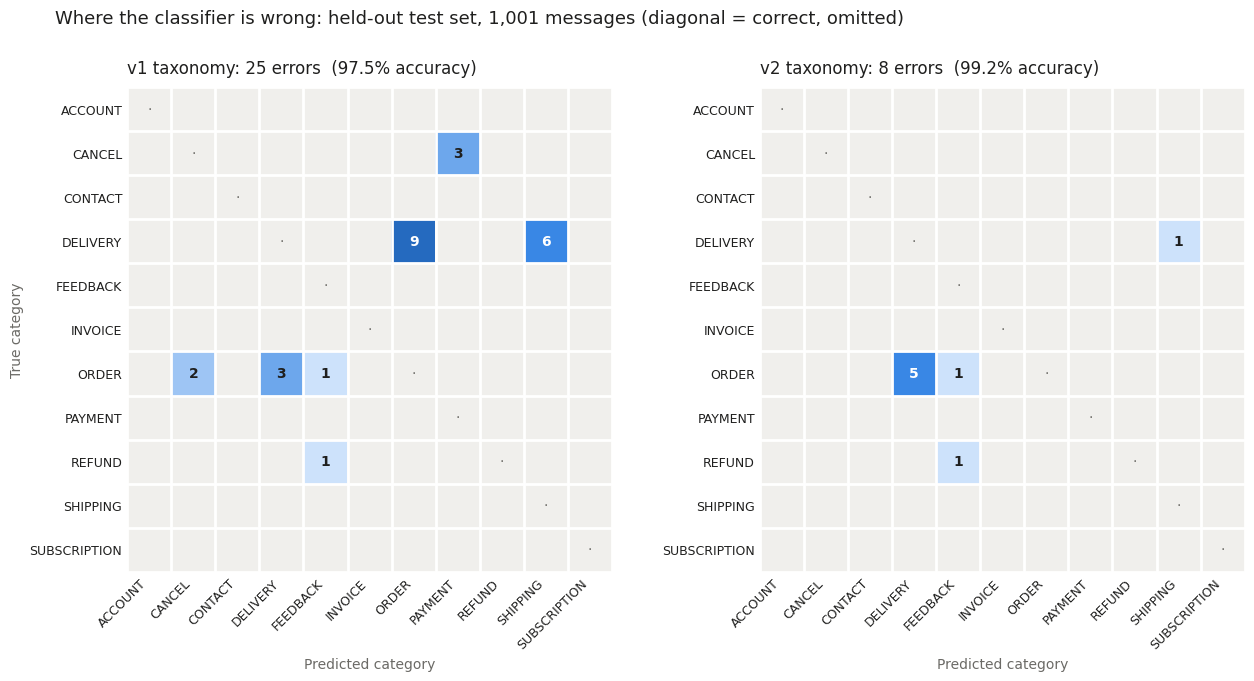

In [11]:
# --- Step 9: error matrices for the README (v1 vs v2, test set) ---
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

INK, MUTED, GRID = '#1f1f1e', '#6b6a66', '#f0efec'
BLUES = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95']   # one hue, light -> dark
labels = sorted(TAXONOMY_V1)

def error_matrix(df):
    m = pd.crosstab(df.category, df.predicted).reindex(index=labels, columns=labels, fill_value=0)
    a = m.to_numpy().copy()
    np.fill_diagonal(a, 0)                   # keep only the mistakes
    return pd.DataFrame(a, index=labels, columns=labels)

m1, m2 = error_matrix(t1), error_matrix(t2)
vmax = max(m1.values.max(), m2.values.max())
bounds = [0.5, 1.5, 2.5, 4.5, 6.5, 9.5, max(vmax, 10) + 0.5]   # 1, 2, 3-4, 5-6, 7-9, 10+
cmap, norm = ListedColormap(BLUES), BoundaryNorm(bounds, len(BLUES))

fig, axes = plt.subplots(1, 2, figsize=(13, 6.4), facecolor='white')
for ax, m, title, acc in [(axes[0], m1, 'v1 taxonomy', t1.correct.mean()),
                          (axes[1], m2, 'v2 taxonomy', t2.correct.mean())]:
    vals = np.ma.masked_equal(m.values, 0)
    ax.set_facecolor('white')
    ax.imshow(np.zeros_like(m.values), cmap=ListedColormap([GRID]), vmin=0, vmax=1)   # empty cells
    ax.imshow(vals, cmap=cmap, norm=norm)
    for i in range(len(labels)):
        for j in range(len(labels)):
            v = m.values[i, j]
            if i == j:
                ax.text(j, i, '·', ha='center', va='center', color=MUTED, fontsize=10)
            elif v:
                ax.text(j, i, str(v), ha='center', va='center', fontsize=10, fontweight='bold',
                        color='white' if v >= 5 else INK)
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right', fontsize=9, color=INK)
    ax.set_yticks(range(len(labels)), labels, fontsize=9, color=INK)
    ax.set_xticks(np.arange(-.5, len(labels)), minor=True)
    ax.set_yticks(np.arange(-.5, len(labels)), minor=True)
    ax.grid(which='minor', color='white', linewidth=2)            # 2px gap between cells
    ax.tick_params(which='both', length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xlabel('Predicted category', color=MUTED, fontsize=10)
    ax.set_title(f'{title}: {int(m.values.sum())} errors  ({acc:.1%} accuracy)',
                 loc='left', fontsize=12, color=INK, pad=10)
axes[0].set_ylabel('True category', color=MUTED, fontsize=10)
fig.suptitle('Where the classifier is wrong: held-out test set, 1,001 messages (diagonal = correct, omitted)',
             x=0.06, y=1.03, ha='left', fontsize=13, color=INK)
fig.tight_layout()

os.makedirs('images', exist_ok=True)
fig.savefig('images/ws1_error_matrix_test.png', dpi=160, bbox_inches='tight')
fig.savefig(f'{CACHE_DIR}/ws1_error_matrix_test.png', dpi=160, bbox_inches='tight')
plt.show()